Predicting Optimal Planting Seasons for Major Bangladeshi Crops Using Machine Learning and Historical Weather Patterns

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

In [2]:
agr = pd.read_csv("agricultural_data.csv")

In [3]:
agr.head()

,Transplant,Products name,Crops Type,Max Temp,Min Temp,Min Relative Humidity,Max Relative Humidity,Transplant_en
0,March,Aus Rice(Local: Broadcasted),Cereals,40.0,12.0,60,85,3
1,March,Aus Rice(HYV: Transplant),Cereals,40.0,12.0,60,85,3
2,March,Maize 2,Cereals,34.0,20.0,60,85,3
3,Feb,Mungbean 2,Pulses,30.0,20.0,20,85,2
4,July,Soybean 2,Oil Seeds,35.0,15.0,35,80,7


In [4]:
agr.shape

(103, 8)

In [5]:
agr['Products name'].nunique()

103

In [6]:
agr["Transplant"].nunique()

12

In [7]:
agr['Crops Type'].unique()

array(['Cereals', 'Pulses', 'Oil Seeds', 'Vegetables', 'Fibre', 'Staple',
       'Fruits', 'Tubers', 'Nicotine'], dtype=object)

In [8]:
agr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103 entries, 0 to 102
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Transplant             103 non-null    object 
 1   Products name          103 non-null    object 
 2   Crops Type             103 non-null    object 
 3   Max Temp               103 non-null    float64
 4   Min Temp               103 non-null    float64
 5   Min Relative Humidity  103 non-null    int64  
 6   Max Relative Humidity  103 non-null    int64  
 7   Transplant_en          103 non-null    int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 6.6+ KB


In [9]:
agr.columns

Index(['Transplant', 'Products name', 'Crops Type', 'Max Temp', 'Min Temp',
       'Min Relative Humidity', 'Max Relative Humidity', 'Transplant_en'],
      dtype='object')

In [10]:
agr.describe()

,Max Temp,Min Temp,Min Relative Humidity,Max Relative Humidity,Transplant_en
count,103.000000,103.000000,103.000000,103.000000,103.000000
mean,30.446602,16.082524,60.805825,83.029126,7.058252
std,6.174708,5.619075,16.219728,10.900132,3.277449
min,15.000000,5.000000,20.000000,45.000000,1.000000
25%,25.000000,11.000000,50.000000,80.000000,4.000000
50%,30.000000,18.000000,65.000000,85.000000,9.000000
75%,35.000000,20.000000,70.000000,90.000000,10.000000
max,47.000000,27.000000,85.000000,100.000000,12.000000


In [11]:
agr.groupby("Crops Type").agg({'Transplant_en': "count", 'Products name': "count", 'Max Temp': "max", \
                               'Min Temp': "min", 'Max Relative Humidity': "max", 'Min Relative Humidity': "min" })

,Transplant_en,Products name,Max Temp,Min Temp,Max Relative Humidity,Min Relative Humidity
Crops Type,,,,,,
Cereals,8,8,40.0,12.0,95,50
Fibre,4,4,40.0,18.0,80,43
Fruits,27,27,47.0,5.0,95,40
Nicotine,1,1,20.0,15.0,85,50
Oil Seeds,10,10,35.0,10.0,95,30
Pulses,5,5,35.0,10.0,95,20
Staple,1,1,32.0,27.0,75,65
Tubers,1,1,26.5,15.0,90,85
Vegetables,46,46,45.0,5.0,100,20


In [12]:
temp = pd.read_csv("BD_weather.csv")

In [13]:
temp.head()

,Station,Year,Month,Day,Rainfall,Sunshine,Humidity,Temperature
0,Ambaganctg,2008,1,1,0.0,9.1,78.0,20.1
1,Ambaganctg,2008,1,2,0.0,5.6,79.0,21.0
2,Ambaganctg,2008,1,3,0.0,8.6,82.0,20.1
3,Ambaganctg,2008,1,4,0.0,9.1,73.0,21.0
4,Ambaganctg,2008,1,5,0.0,9.4,67.0,20.3


In [14]:
class_label = np.array(["January", "February", "March", "April", "May", "June", "July", "August", "September","October", "November", "December"])

In [15]:
temp.describe()

,Year,Month,Day,Rainfall,Sunshine,Humidity,Temperature
count,543839.000000,543839.000000,543839.000000,543839.000000,543839.000000,543839.000000,543839.000000
mean,2000.684083,6.523081,15.729192,6.732987,6.279590,79.848704,25.570680
std,14.694441,3.448665,8.799912,19.366711,3.350863,8.937966,4.166981
min,1961.000000,1.000000,1.000000,0.000000,0.000000,10.000000,0.000000
25%,1990.000000,4.000000,8.000000,0.000000,3.800000,75.000000,22.600000
50%,2002.000000,7.000000,16.000000,0.000000,7.200000,81.000000,26.900000
75%,2013.000000,10.000000,23.000000,3.000000,9.000000,86.000000,28.800000
max,2023.000000,12.000000,31.000000,590.000000,90.200000,100.000000,37.800000


In [28]:
temp_modify = temp.groupby(["Station","Year","Month"], as_index = False).agg({'Rainfall' : "mean", 'Sunshine': "mean", 'Humidity': "mean",
       'Temperature': "mean"})

In [29]:
temp_modify.describe()

,Year,Month,Rainfall,Sunshine,Humidity,Temperature
count,17868.000000,17868.000000,17868.000000,17868.000000,17868.000000,17868.000000
mean,2000.684352,6.500000,6.700903,6.288241,79.804572,25.557609
std,14.695285,3.452149,8.230337,1.872345,6.911506,3.847678
min,1961.000000,1.000000,0.000000,0.000000,44.935484,0.000000
25%,1990.000000,3.750000,0.290323,4.845161,75.741935,22.688738
50%,2002.000000,6.500000,3.774194,6.477419,80.966667,27.309677
75%,2013.000000,9.250000,10.258065,7.746667,85.066667,28.506452
max,2023.000000,12.000000,100.033333,12.269000,97.064516,33.293226


In [16]:
Ambagan = temp[temp["Station"] == "Ambaganctg"]
Barisal = temp[temp["Station"] == "Barisal"]
Bhola = temp[temp["Station"] == 'Bhola']
Bogra = temp[temp["Station"] == 'Bogra']
Chandpur = temp[temp["Station"] == 'Chandpur']
Chittagong = temp[temp["Station"] == 'Chittagong']
Chuadanga = temp[temp["Station"] == 'Chuadanga']
Comilla = temp[temp["Station"] == 'Comilla']
Coxsbazar = temp[temp["Station"] == 'Coxsbazar']
Dhaka = temp[temp["Station"] == 'Dhaka']
Dinajpur = temp[temp["Station"] == 'Dinajpur']
Faridpur = temp[temp["Station"] == 'Faridpur']
Feni = temp[temp["Station"] == 'Feni']
Hatiya = temp[temp["Station"] == 'Hatiya']
Ishurdi = temp[temp["Station"] == 'Ishurdi']
Jessore = temp[temp["Station"] == 'Jessore']
Khepupara = temp[temp["Station"] == 'Khepupara']
Khulna = temp[temp["Station"] == 'Khulna']
Kutubdia = temp[temp["Station"] == 'Kutubdia']
Madaripur = temp[temp["Station"] == 'Madaripur']
Mcourt = temp[temp["Station"] == 'Mcourt']
Mongla = temp[temp["Station"] == 'Mongla']
Mymensingh = temp[temp["Station"] == 'Mymensingh']
Patuakhali = temp[temp["Station"] == 'Patuakhali']
Rajshahi = temp[temp["Station"] == 'Rajshahi']
Rangamati = temp[temp["Station"] == 'Rangamati']
Rangpur = temp[temp["Station"] == 'Rangpur']
Sandwip = temp[temp["Station"] == 'Sandwip']
Satkhira = temp[temp["Station"] == 'Satkhira']
Sitakunda = temp[temp["Station"] == 'Sitakunda']
Srimangal = temp[temp["Station"] == 'Srimangal']
Sydpur = temp[temp["Station"] == 'Sydpur']
Sylhet = temp[temp["Station"] == 'Sylhet']
Tangail = temp[temp["Station"] == 'Tangail']
Teknaf = temp[temp["Station"] == 'Teknaf']

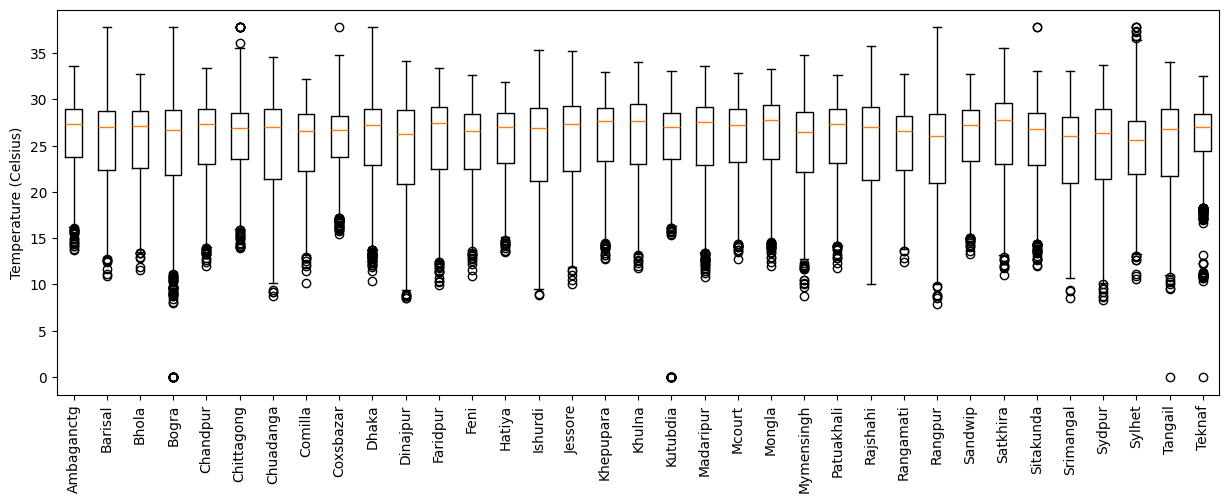

In [17]:
fig, ax = plt.subplots(figsize = (15, 5))
ax.boxplot([Ambagan["Temperature"], Barisal["Temperature"], Bhola["Temperature"], Bogra["Temperature"], Chandpur["Temperature"],\
           Chittagong["Temperature"],Chuadanga["Temperature"],Comilla["Temperature"],Coxsbazar["Temperature"],Dhaka["Temperature"],\
            Dinajpur["Temperature"],Faridpur["Temperature"],Feni["Temperature"],Hatiya["Temperature"],Ishurdi["Temperature"],\
            Jessore["Temperature"],Khepupara["Temperature"],Khulna["Temperature"],Kutubdia["Temperature"],Madaripur["Temperature"],\
            Mcourt["Temperature"],Mongla["Temperature"],Mymensingh["Temperature"],Patuakhali["Temperature"],\
           Rajshahi["Temperature"],Rangamati["Temperature"],Rangpur["Temperature"],Sandwip["Temperature"],Satkhira["Temperature"],\
            Sitakunda["Temperature"],Srimangal["Temperature"],Sydpur["Temperature"],Sylhet["Temperature"],Tangail["Temperature"],\
            Teknaf["Temperature"]])
ax.set_xticklabels(['Ambaganctg', 'Barisal', 'Bhola', 'Bogra', 'Chandpur',
       'Chittagong', 'Chuadanga', 'Comilla', 'Coxsbazar', 'Dhaka',
       'Dinajpur', 'Faridpur', 'Feni', 'Hatiya', 'Ishurdi', 'Jessore',
       'Khepupara', 'Khulna', 'Kutubdia', 'Madaripur', 'Mcourt', 'Mongla',
       'Mymensingh', 'Patuakhali', 'Rajshahi', 'Rangamati', 'Rangpur',
       'Sandwip', 'Satkhira', 'Sitakunda', 'Srimangal', 'Sydpur',
       'Sylhet', 'Tangail', 'Teknaf'], rotation = 90)
ax.set_ylabel("Temperature (Celsius)")
plt.savefig("tem_boxplot.jpg", bbox_inches='tight')
plt.show()

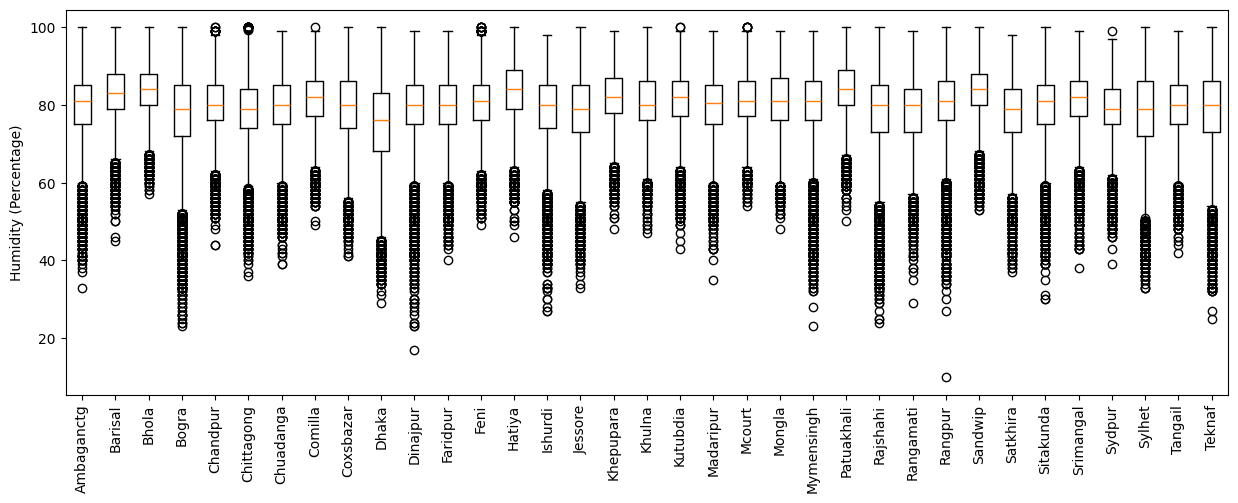

In [18]:
fig, ax = plt.subplots(figsize = (15, 5))
ax.boxplot([Ambagan["Humidity"], Barisal["Humidity"], Bhola["Humidity"], Bogra["Humidity"], Chandpur["Humidity"],\
           Chittagong["Humidity"],Chuadanga["Humidity"],Comilla["Humidity"],Coxsbazar["Humidity"],Dhaka["Humidity"],\
            Dinajpur["Humidity"],Faridpur["Humidity"],Feni["Humidity"],Hatiya["Humidity"],Ishurdi["Humidity"],\
            Jessore["Humidity"],Khepupara["Humidity"],Khulna["Humidity"],Kutubdia["Humidity"],Madaripur["Humidity"],\
            Mcourt["Humidity"],Mongla["Humidity"],Mymensingh["Humidity"],Patuakhali["Humidity"],\
           Rajshahi["Humidity"],Rangamati["Humidity"],Rangpur["Humidity"],Sandwip["Humidity"],Satkhira["Humidity"],\
            Sitakunda["Humidity"],Srimangal["Humidity"],Sydpur["Humidity"],Sylhet["Humidity"],Tangail["Humidity"],\
            Teknaf["Humidity"]])
ax.set_xticklabels(['Ambaganctg', 'Barisal', 'Bhola', 'Bogra', 'Chandpur',
       'Chittagong', 'Chuadanga', 'Comilla', 'Coxsbazar', 'Dhaka',
       'Dinajpur', 'Faridpur', 'Feni', 'Hatiya', 'Ishurdi', 'Jessore',
       'Khepupara', 'Khulna', 'Kutubdia', 'Madaripur', 'Mcourt', 'Mongla',
       'Mymensingh', 'Patuakhali', 'Rajshahi', 'Rangamati', 'Rangpur',
       'Sandwip', 'Satkhira', 'Sitakunda', 'Srimangal', 'Sydpur',
       'Sylhet', 'Tangail', 'Teknaf'], rotation = 90)
ax.set_ylabel("Humidity (Percentage)")
plt.savefig("himidity_boxplot.jpg", bbox_inches='tight')
plt.show()

<Figure size 5e+09x500 with 0 Axes>

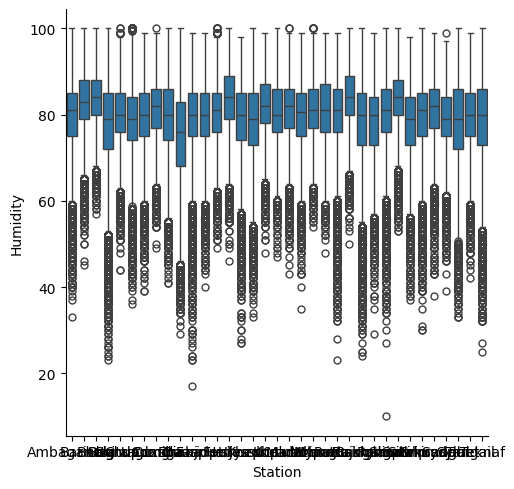

In [19]:
plt.figure(figsize = (50000000,5))
sns.catplot(x = "Station", y = "Humidity", data = temp, kind = "box")
plt.show()

In [20]:
station = temp.groupby("Station", as_index = False).agg({"Rainfall": "mean", "Humidity" : "mean", "Temperature" : "mean"})
station

,Station,Rainfall,Humidity,Temperature
0,Ambaganctg,8.168378,79.419233,26.174076
1,Barisal,5.645972,83.132402,25.486149
2,Bhola,6.061318,83.614390,25.574995
3,Bogra,4.789937,77.296432,25.248424
4,Chandpur,6.016370,79.950891,25.898979
5,Chittagong,7.897048,78.848617,25.861177
6,Chuadanga,4.007885,79.463038,25.148790
7,Comilla,5.760076,81.207705,25.265025
8,Coxsbazar,9.926897,79.786790,25.876553
9,Dhaka,5.507048,74.615072,25.835671


C:\Users\ACCESS\AppData\Local\Temp\ipykernel_6932\3853338464.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(station.Station, rotation = 90)


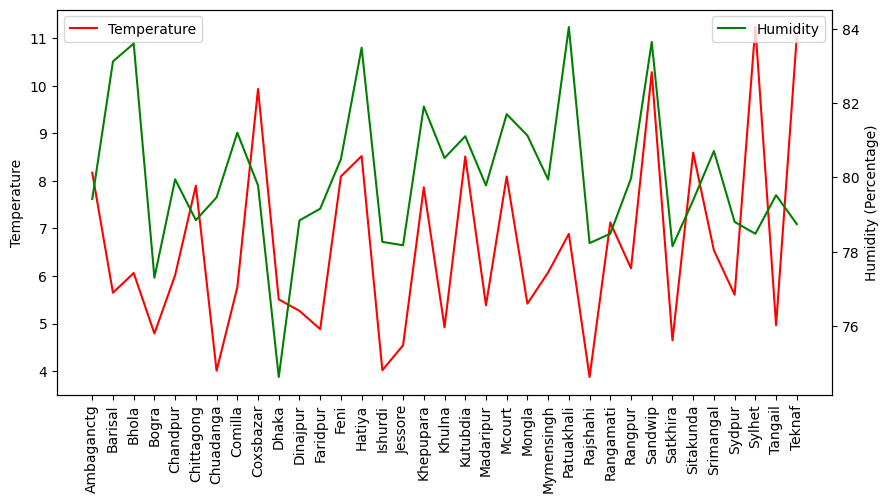

In [21]:
fig, ax = plt.subplots(figsize = (10, 5))
ax.plot(station.Station, station.Rainfall, color = "r", label = "Temperature")
ax.set_ylabel("Temperature")
ax.set_xticklabels(station.Station, rotation = 90)
plt.legend()
ax2 = ax.twinx()
ax2.plot(station.Station, station.Humidity, color = "g", label = "Humidity")
ax2.set_ylabel("Humidity (Percentage)")
plt.legend()
plt.show()

In [22]:
temp_75 = temp.groupby("Year", as_index = False)["Temperature"].quantile(0.75)

In [23]:
temp_25 = temp.groupby("Year", as_index = False)["Temperature"].quantile(0.25)

In [24]:
avg_temp = temp.groupby("Year", as_index = False)["Temperature"].mean()

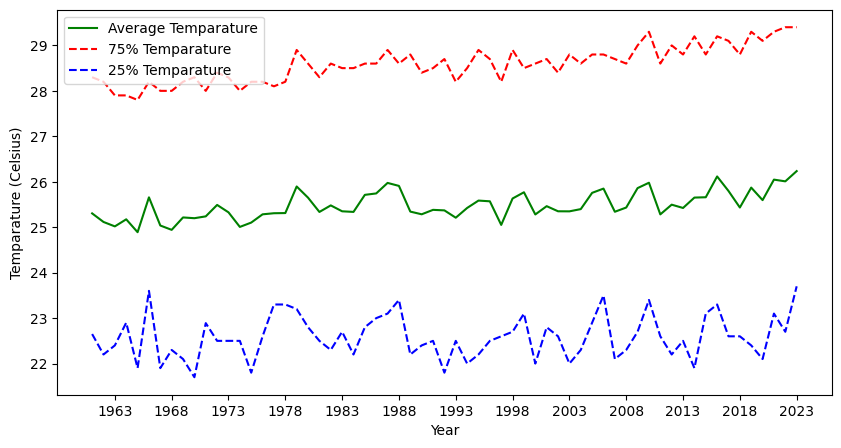

In [25]:
fig, ax = plt.subplots(figsize = (10,5))
ax.plot( avg_temp.Year, avg_temp["Temperature"], label = "Average Temparature", color = "g")
ax.plot( temp_75.Year, temp_75["Temperature"], label = "75% Temparature", color = "r", linestyle = "--")
ax.plot( temp_25.Year, temp_25["Temperature"], label = "25% Temparature", color = "b", linestyle = "--")
plt.xticks([1963, 1968, 1973, 1978, 1983, 1988, 1993, 1998, 2003, 2008, 2013, 2018, 2023])
plt.xlabel("Year")
plt.ylabel("Temparature (Celsius)")
plt.legend()
plt.savefig("avg_temp.jpg", bbox_inches='tight')
plt.show()

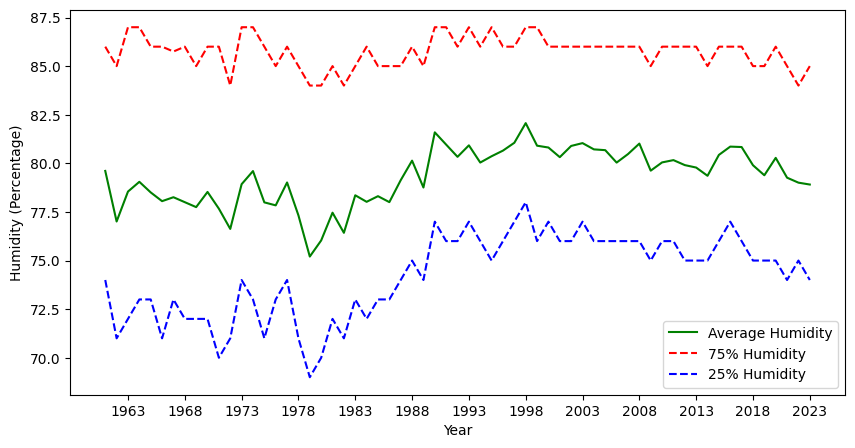

In [26]:
humidity_75 = temp.groupby("Year", as_index = False)["Humidity"].quantile(0.75)
humidity_25 = temp.groupby("Year", as_index = False)["Humidity"].quantile(0.25)
avg_humidity = temp.groupby("Year", as_index = False)["Humidity"].mean()


fig, ax = plt.subplots(figsize = (10,5))
ax.plot( avg_humidity.Year, avg_humidity["Humidity"], label = "Average Humidity", color = "g")
ax.plot( humidity_75.Year, humidity_75["Humidity"], label = "75% Humidity", color = "r", linestyle = "--")
ax.plot( humidity_25.Year, humidity_25["Humidity"], label = "25% Humidity", color = "b", linestyle = "--")
plt.xticks([1963, 1968, 1973, 1978, 1983, 1988, 1993, 1998, 2003, 2008, 2013, 2018, 2023])
plt.xlabel("Year")
plt.ylabel("Humidity (Percentage)")
plt.legend()
plt.savefig("avg_humidity.jpg", bbox_inches='tight')
plt.show()

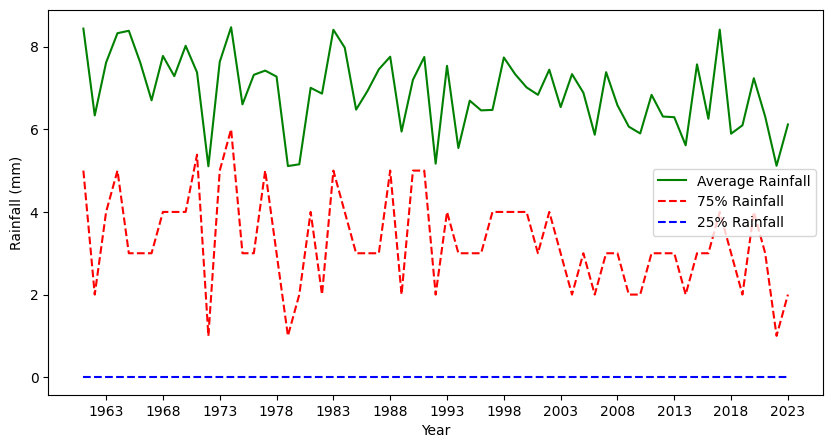

In [27]:
rain_75 = temp.groupby("Year", as_index = False)["Rainfall"].quantile(0.75)
rain_25 = temp.groupby("Year", as_index = False)["Rainfall"].quantile(0.25)
avg_rain = temp.groupby("Year", as_index = False)["Rainfall"].mean()


fig, ax = plt.subplots(figsize = (10,5))
ax.plot( avg_rain.Year, avg_rain["Rainfall"], label = "Average Rainfall", color = "g")
ax.plot( rain_75.Year, rain_75["Rainfall"], label = "75% Rainfall", color = "r", linestyle = "--")
ax.plot( rain_25.Year, rain_25["Rainfall"], label = "25% Rainfall", color = "b", linestyle = "--")
plt.xticks([1963, 1968, 1973, 1978, 1983, 1988, 1993, 1998, 2003, 2008, 2013, 2018, 2023])
plt.xlabel("Year")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.savefig("avg_rainfall", bbox_inches = "tight")
plt.show()